<div style="background:linear-gradient(120deg,#0a2a5c,#1c5aa6);color:#fff;padding:22px 26px;border-radius:12px;border-bottom:5px solid #d49a2a;">
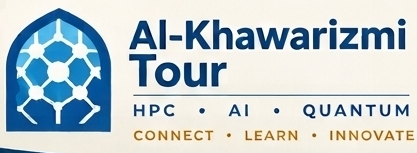
<p style="color:#ffd98e;letter-spacing:.14em;font-size:12px;font-weight:700;margin:12px 0 4px;">AL-KHAWARIZMI TOUR · ONLINE HACKATHON HPC &amp; AI · OCT 3 – NOV 7, 2026 · LECTURE 1 NOTEBOOK</p>
<h1 style="color:#fff;margin:4px 0 6px;border:none;">Data Quality &amp; Preprocessing — Beijing Air Quality · Hands-on &amp; Week-1 Team Challenge</h1>
<p style="color:#e6eef8;margin:0;">Part A: guided demos used during the lecture (slide references in each heading) · Part B: the week-long <b>Air-Quality Data Challenge</b></p>
<p style="color:#ffd98e;margin:10px 0 0;font-style:italic;">Connect · Learn · Innovate — Instructor: Dr. Rafik Borji</p></div>

## How to use this notebook

| Part | When | What |
|---|---|---|
| **A · Guided demos** (A1–A11) | during the 2-hour lecture | each demo matches a slide of the deck / a card of the speaker script |
| **B · Team challenge** (Tasks 1–6 + ★ bonus) | the whole week | fill in the `# TODO` cells, write your report, prepare your pitch |

**Dataset:** *Beijing Multi-Site Air Quality* — UCI Machine Learning Repository, dataset 501. Hourly PM2.5, PM10, SO2, NO2, CO, O3 (µg/m³) and TEMP, PRES, DEWP, RAIN, wind direction `wd`, wind speed `WSPM` at **12 stations**, **1 Mar 2013 – 28 Feb 2017**, **420,768 rows**, with real missing values (NA).
Reference: Zhang, S. et al. (2017) *Cautionary tales on air-quality improvement in Beijing*, Proc. R. Soc. A.

**Data access:** the notebook downloads the archive from UCI (≈ 8 MB) and caches it. If you already have the `PRSA_Data_*.csv` files, put them next to the notebook. Offline, a synthetic stand-in with the same columns is generated so the code still runs.

**Requirements:** Python ≥ 3.9, `numpy`, `pandas`, `matplotlib`, `scikit-learn ≥ 1.2`. Works in Jupyter, VS Code or Google Colab. Tip: on a laptop, run Part A first on `SAMPLE_STATIONS` (4 stations) and switch to all 12 for the challenge.

## 0 · Setup — set your team number first

In [ ]:
TEAM_ID = 1102     
SEED = 1000 + TEAM_ID
TEAM_NAME = "we_tried"

import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": .3})
rng = np.random.default_rng(SEED)
import sklearn; print("scikit-learn", sklearn.__version__, "| team", TEAM_ID)

scikit-learn 1.9.1 | team 1102


---
# Part A · Guided demos
## A1 · Load the 12 station files  *(slides 2 & 13)*

In [6]:
import io, os, glob, ssl, zipfile, urllib.request

STATIONS = ["Aotizhongxin", "Changping", "Dingling", "Dongsi", "Guanyuan", "Gucheng", "Huairou",
            "Nongzhanguan", "Shunyi", "Tiantan", "Wanliu", "Wanshouxigong"]
WD = ["N", "NNE", "NE", "ENE", "E", "ESE", "SE", "SSE", "S", "SSW", "SW", "WSW", "W", "WNW", "NW", "NNW"]
POLLUTANTS = ["PM2.5", "PM10", "SO2", "NO2", "CO", "O3"]
WEATHER = ["TEMP", "PRES", "DEWP", "RAIN", "WSPM"]
KEY = ["station", "year", "month", "day", "hour"]
URL = "https://archive.ics.uci.edu/static/public/501/beijing+multi+site+air+quality+data.zip"
CACHE = "beijing_air_quality_raw.csv.gz"

def _csvs_from_zip(blob):
    """The UCI archive contains a nested zip with one CSV per station -> read them all."""
    frames = []
    with zipfile.ZipFile(io.BytesIO(blob)) as z:
        for name in z.namelist():
            if name.lower().endswith(".zip"):
                frames += _csvs_from_zip(z.read(name))
            elif name.lower().endswith(".csv") and "PRSA_Data" in os.path.basename(name):
                frames.append(pd.read_csv(io.BytesIO(z.read(name))))
    return frames

def _download(url):
    try:
        return urllib.request.urlopen(url, timeout=180).read()
    except Exception:
        return urllib.request.urlopen(url, timeout=180, context=ssl._create_unverified_context()).read()

def synthetic_beijing(seed=0):
    """Offline stand-in with the same columns, 12 stations, seasonal/diurnal cycles and runs of missing values.
    Used ONLY if neither local files nor the UCI download are available."""
    r = np.random.default_rng(seed)
    t = pd.date_range("2013-03-01 00:00", "2017-02-28 23:00", freq="h")
    n, doy, hr = len(t), t.dayofyear.values, t.hour.values
    season = np.cos(2 * np.pi * (doy - 15) / 365.25)                 # +1 in mid-January (heating season)
    e = r.normal(0, 1, n); z = np.zeros(n)
    for i in range(1, n):                                            # regional stagnation index, AR(1)
        z[i] = 0.985 * z[i - 1] + 0.17 * e[i]
    frames = []
    for k, st in enumerate(STATIONS):
        urb = 1.0 if st in ["Dongsi", "Guanyuan", "Gucheng", "Nongzhanguan", "Tiantan", "Wanshouxigong", "Aotizhongxin", "Wanliu"] else 0.0
        TEMP = 13 - 15 * season + 4 * np.sin(2 * np.pi * (hr - 9) / 24) + r.normal(0, 2, n) - (1 - urb)
        DEWP = TEMP - np.clip(r.gamma(2, 4, n) - 3 * z, 0.5, 35)
        PRES = 1012 + 12 * season + r.normal(0, 3, n)
        WSPM = np.clip(r.gamma(2, 0.9, n) - 0.4 * z, 0, None)
        ang = (np.where(z < 0, 315, 180) + r.normal(0, 50, n)) % 360
        wd = np.array(WD)[np.round(ang / 22.5).astype(int) % 16]
        RAIN = np.where(r.random(n) < 0.03 * (1 - season), r.exponential(1.5, n), 0.0)
        logpm = 3.8 + 0.35 * season + 0.9 * z + 0.15 * urb + 0.2 * np.cos(2 * np.pi * (hr - 22) / 24) - 0.15 * WSPM + r.normal(0, .25, n)
        PM25 = np.clip(np.exp(logpm), 3, 900)
        PM10 = PM25 * (1.15 + r.gamma(2, 0.2, n))
        CO = np.clip(300 + 11 * PM25 * (1 + .3 * season) + r.normal(0, 150, n), 100, None)
        NO2 = np.clip(20 + .35 * PM25 ** .8 + 10 * urb + r.normal(0, 8, n), 2, None)
        SO2 = np.clip(3 + 25 * np.clip(season, 0, None) * np.exp(.5 * z) + r.normal(0, 3, n), 2, None)
        O3 = np.clip(10 + 60 * (1 - season) / 2 * 2 * np.clip(np.sin(2 * np.pi * (hr - 8) / 24), 0, None) - .2 * NO2 + r.normal(0, 10, n), 2, None)
        f = pd.DataFrame({"No": np.arange(1, n + 1), "year": t.year, "month": t.month, "day": t.day, "hour": hr,
                          "PM2.5": PM25, "PM10": PM10, "SO2": SO2, "NO2": NO2, "CO": CO, "O3": O3,
                          "TEMP": TEMP, "PRES": PRES, "DEWP": DEWP, "RAIN": RAIN, "wd": wd, "WSPM": WSPM, "station": st}).round(1)
        for c in POLLUTANTS + WEATHER + ["wd"]:                       # runs of missing values
            for s0 in r.choice(n, 25, replace=False):
                f.loc[s0:s0 + int(r.geometric(0.08)), c] = np.nan
        frames.append(f)
    return frames

def load_beijing():
    local = sorted(glob.glob("**/PRSA_Data_*.csv", recursive=True))
    if local:
        frames = [pd.read_csv(f) for f in local]; src = f"{len(local)} local station files"
    elif os.path.exists(CACHE):
        return pd.read_csv(CACHE)
    else:
        try:
            frames = _csvs_from_zip(_download(URL)); src = "UCI download"
        except Exception as e:
            print("UCI not reachable (", type(e).__name__, ")"); frames = []
        if not frames:
            frames = synthetic_beijing(); src = "SYNTHETIC offline stand-in"
    df = pd.concat(frames, ignore_index=True)
    if src == "UCI download":
        df.to_csv(CACHE, index=False)
    print(f"Loaded {df.shape[0]:,} rows x {df.shape[1]} columns from {src}")
    return df

raw = load_beijing()
raw["datetime"] = pd.to_datetime(raw[["year", "month", "day", "hour"]])
raw.head()

Loaded 420,768 rows x 18 columns from UCI download


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station,datetime
0,1,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin,2013-03-01 00:00:00
1,2,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin,2013-03-01 01:00:00
2,3,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin,2013-03-01 02:00:00
3,4,2013,3,1,3,6.0,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,NW,3.1,Aotizhongxin,2013-03-01 03:00:00
4,5,2013,3,1,4,3.0,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,N,2.0,Aotizhongxin,2013-03-01 04:00:00


## A2 · The scenario: a careless merge + an untouched final year  *(slides 27 & 32)*
* **Test year** = 1 Mar 2016 – 28 Feb 2017 (the real data, untouched) — used **only in Task 6**.
* **Training years** = 1 Mar 2013 – 29 Feb 2016 → turned into your team's *merged export* with realistic merge errors.

In [7]:
SPLIT = pd.Timestamp("2016-03-01")
train_raw = raw[raw["datetime"] < SPLIT].reset_index(drop=True)
test_year = raw[raw["datetime"] >= SPLIT].reset_index(drop=True)
print(f"training years: {len(train_raw):,} rows | test year: {len(test_year):,} rows")

training years: 315,648 rows | test year: 105,120 rows


## A3 · Generate your team's merged export
The function reproduces problems of a careless multi-station merge. **Treat it as a black box during the challenge** — your job is to *discover* the problems from the data.

In [8]:
def make_dirty(df, seed):
    r = np.random.default_rng(seed)
    d = df.drop(columns=["datetime"]).copy()
    n = len(d)
    st_unit, st_tz, st_stuck = r.choice(STATIONS, 3, replace=False)
    # 1) consistency: station-name variants and lower-case wind directions
    v = r.random(n)
    d.loc[v < .05, "station"] = d.loc[v < .05, "station"].str.upper()
    d.loc[(v >= .05) & (v < .10), "station"] = d.loc[(v >= .05) & (v < .10), "station"].str.lower() + " "
    w = r.random(n) < .02
    d.loc[w, "wd"] = d.loc[w, "wd"].str.lower()
    stn = d["station"].str.strip().str.title()
    # 2) accuracy: one station exported CO in mg/m3 during 2014
    m = (stn == st_unit) & (d["year"] == 2014)
    d.loc[m, "CO"] = d.loc[m, "CO"] / 1000
    # 3) timeliness: one station exported in UTC during 2015 (8 h behind Beijing time)
    m = (stn == st_tz) & (d["year"] == 2015)
    dt = pd.to_datetime(d.loc[m, ["year", "month", "day", "hour"]]) - pd.Timedelta(hours=8)
    d.loc[m, "year"], d.loc[m, "month"], d.loc[m, "day"], d.loc[m, "hour"] = dt.dt.year, dt.dt.month, dt.dt.day, dt.dt.hour
    # 4) validity: stuck PM2.5 sensor (flat lines), sentinel codes, PM2.5/PM10 column swap
    idx = np.flatnonzero((stn == st_stuck).values)
    for s0 in r.choice(idx[:-80], 8, replace=False):
        L = int(r.integers(24, 73)); rows = d.index[s0:s0 + L]
        d.loc[rows, "PM2.5"] = d.loc[rows[0], "PM2.5"]
    for c in ["TEMP", "PRES"]:
        d.loc[r.random(n) < .002, c] = -999
    sw = r.random(n) < .003
    d.loc[sw, ["PM2.5", "PM10"]] = d.loc[sw, ["PM10", "PM2.5"]].values
    # 5) completeness: extra random logger drop-outs in NO2
    d.loc[r.random(n) < .03, "NO2"] = np.nan
    # 6) uniqueness: one station-month re-uploaded (slightly different O3) + scattered exact duplicates
    s_dup = r.choice(STATIONS); y_dup, m_dup = 2014, int(r.integers(1, 13))
    re = d[(stn == s_dup) & (d["year"] == y_dup) & (d["month"] == m_dup)].copy()
    re["O3"] = re["O3"] + 1
    d = pd.concat([d, re, d.sample(frac=.005, random_state=seed)], ignore_index=True)
    return d.sample(frac=1, random_state=seed).reset_index(drop=True)

dirty = make_dirty(train_raw, SEED)
dirty.to_csv(f"beijing_merged_team{TEAM_ID}.csv.gz", index=False)
print(f"merged export: {dirty.shape[0]:,} rows -> beijing_merged_team{TEAM_ID}.csv.gz")
dirty.head()

merged export: 317,946 rows -> beijing_merged_team1102.csv.gz


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,3416,2013,7,21,7,87.0,110.0,6.0,29.0,1200.0,40.0,25.6,997.0,22.1,0.0,E,1.5,Huairou
1,251,2013,3,11,10,108.0,145.0,43.0,66.0,1100.0,100.0,6.3,1012.9,-8.4,0.0,se,2.2,Dingling
2,2625,2013,6,18,8,26.0,35.0,10.0,59.0,500.0,56.0,29.2,990.7,14.2,0.0,SE,1.6,Gucheng
3,20898,2015,7,19,17,68.0,68.0,2.0,24.0,1000.0,102.0,23.5,1003.2,21.2,0.3,ESE,3.8,Dongsi
4,17762,2015,3,11,1,106.0,123.0,24.0,74.0,1400.0,16.0,-1.1,1021.0,-16.1,0.0,N,1.5,Shunyi


## A4 · First look  *(slides 11, 13 & 14)*

In [9]:
df = dirty.copy()
print("shape:", df.shape, "\n")
print(df.dtypes, "\n")
print("fraction missing:\n", df.isna().mean().round(4).sort_values(ascending=False), "\n")
print("duplicate station-hours:", df.duplicated(subset=KEY).sum())
print("station labels:", df["station"].nunique(), "distinct (expected 12)")

shape: (317946, 18) 

No           int64
year         int64
month        int64
day          int64
hour         int64
PM2.5      float64
PM10       float64
SO2        float64
NO2        float64
CO         float64
O3         float64
TEMP       float64
PRES       float64
DEWP       float64
RAIN       float64
wd             str
WSPM       float64
station        str
dtype: object 

fraction missing:
 NO2        0.0600
CO         0.0574
O3         0.0322
SO2        0.0221
PM2.5      0.0202
PM10       0.0146
wd         0.0021
RAIN       0.0006
DEWP       0.0006
PRES       0.0006
WSPM       0.0006
TEMP       0.0006
year       0.0000
No         0.0000
day        0.0000
month      0.0000
hour       0.0000
station    0.0000
dtype: float64 

duplicate station-hours: 2305
station labels: 36 distinct (expected 12)


In [10]:
# mean vs median per station -> skew; min / max -> impossible values
df.groupby(df["station"].str.strip().str.title())[["PM2.5", "CO", "TEMP", "PRES"]].agg(["mean", "median", "min", "max"]).round(1)

PM2.5                         CO                          TEMP  \
               mean median  min    max    mean  median    min      max  mean   
station                                                                        
Aotizhongxin   84.0   60.0  3.0  898.0  1271.2   900.0  100.0  10000.0  11.5   
Changping      72.5   48.0  2.0  882.0   738.5   400.0    0.1   9900.0  11.1   
Dingling       66.8   41.0  3.0  881.0   907.6   600.0  100.0   9400.0  11.9   
Dongsi         85.6   61.0  3.0  737.0  1339.2  1000.0  100.0  10000.0  10.9   
Guanyuan       82.8   60.0  3.0  680.0  1289.2   900.0  100.0  10000.0  11.6   
Gucheng        83.8   61.0  2.0  770.0  1354.2  1000.0  100.0   9900.0  12.0   
Huairou        71.2   48.0  2.0  762.0  1035.4   800.0  100.0  10000.0  10.1   
Nongzhanguan   84.9   60.0  3.0  844.0  1331.9  1000.0  100.0  10000.0  12.2   
Shunyi         80.1   56.0  3.0  941.0  1187.4   900.0  100.0  10000.0  11.2   
Tiantan        82.8   60.0  2.0  821.0  1306.9  1000.0  100.0  10000.0  11.6   
Wanliu         85.3   61.0  3.0  957.0  1335.0   900.0  100.0  10000.0  11.1   
Wanshouxigong  84.8   61.0  3.0  999.0  1395.6  1000.0  100.0   9800.0  11.1   

                                     PRES                         
              median    min   max    mean  median    min     max  
station                                                           
Aotizhongxin    14.4 -999.0  40.5  1007.5  1011.2 -999.0  1042.0  
Changping       14.6 -999.0  41.4  1003.6  1007.5 -999.0  1036.5  
Dingling        14.6 -999.0  41.4  1003.3  1007.5 -999.0  1036.5  
Dongsi          14.4 -999.0  41.1  1008.4  1012.3 -999.0  1042.0  
Guanyuan        14.3 -999.0  40.5  1008.2  1011.2 -999.0  1042.0  
Gucheng         14.8 -999.0  41.6  1005.6  1008.6 -999.0  1038.1  
Huairou         13.4 -999.0  40.3  1003.4  1007.3 -999.0  1036.5  
Nongzhanguan    15.0 -999.0  41.1  1008.0  1012.1 -999.0  1042.0  
Shunyi          14.3 -999.0  40.6  1008.2  1012.7 -999.0  1042.8  
Tiantan         14.5 -999.0  41.1  1009.0  1012.3 -999.0  1042.0  
Wanliu          14.2 -999.0  40.5  1007.6  1010.8 -999.0  1040.3  
Wanshouxigong   14.6 -999.0  40.6  1006.6  1010.6 -999.0  1042.0

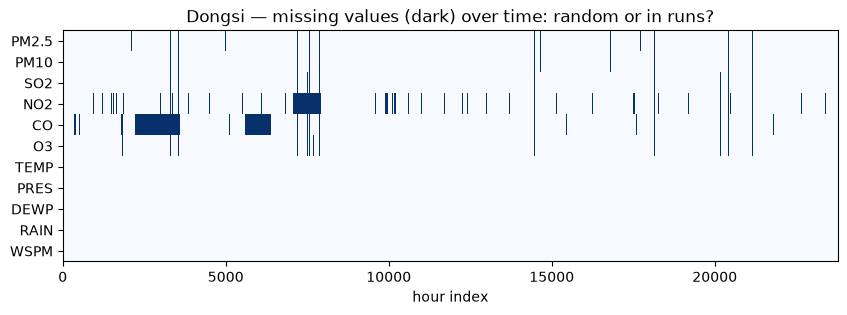

In [11]:
# missing-value matrix for one station (rows = hours in time order)
one = df[df["station"] == "Dongsi"].sort_values(["year", "month", "day", "hour"])
plt.figure(figsize=(10, 3))
plt.imshow(one[POLLUTANTS + WEATHER].isna().values.T, aspect="auto", interpolation="nearest", cmap="Blues")
plt.yticks(range(len(POLLUTANTS + WEATHER)), POLLUTANTS + WEATHER); plt.xlabel("hour index"); plt.grid(False)
plt.title("Dongsi — missing values (dark) over time: random or in runs?"); plt.show()

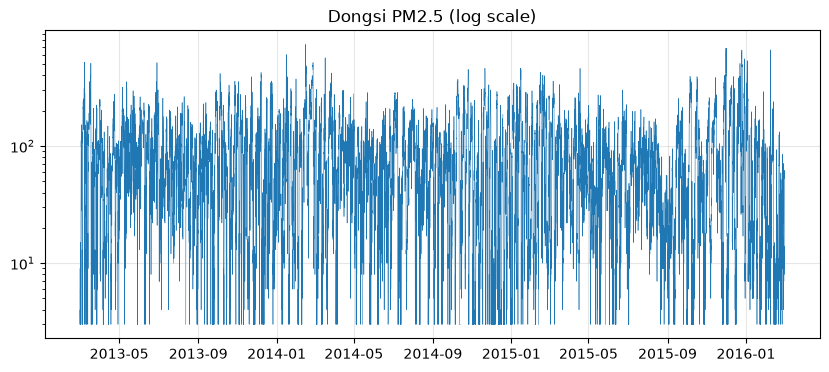

In [12]:
# the single most useful plot: a time series per station
one_dt = pd.to_datetime(one[["year", "month", "day", "hour"]])
plt.plot(one_dt, one["PM2.5"], lw=.4); plt.yscale("log"); plt.title("Dongsi PM2.5 (log scale)"); plt.show()

## A5 · Consistency: canonical labels  *(slide 21)*

In [13]:
print(df["station"].value_counts().head(15))
canon = df["station"].str.strip().str.title()
print("\nafter strip + title:", canon.nunique(), "stations")
print("wind directions:", sorted(df["wd"].dropna().unique()))

station
Nongzhanguan     24451
Shunyi           23871
Aotizhongxin     23842
Changping        23841
Guanyuan         23815
Tiantan          23795
Huairou          23780
Dingling         23776
Dongsi           23773
Wanshouxigong    23730
Wanliu           23725
Gucheng          23723
gucheng           1406
nongzhanguan      1382
wanliu            1379
Name: count, dtype: int64

after strip + title: 12 stations
wind directions: ['E', 'ENE', 'ESE', 'N', 'NE', 'NNE', 'NNW', 'NW', 'S', 'SE', 'SSE', 'SSW', 'SW', 'W', 'WNW', 'WSW', 'e', 'ene', 'ese', 'n', 'ne', 'nne', 'nnw', 'nw', 's', 'se', 'sse', 'ssw', 'sw', 'w', 'wnw', 'wsw']


## A6 · Outliers, stuck sensors and physics checks  *(slides 19 & 20)*

In [14]:
num = df.copy()
checks = {
    "PM2.5 > PM10 (impossible)": int((num["PM2.5"] > num["PM10"]).sum()),
    "negative concentrations":   int((num[POLLUTANTS] < 0).sum().sum()),
    "sentinel -999 codes":       int((num[POLLUTANTS + WEATHER] == -999).sum().sum()),
    "PRES outside 950-1060 hPa": int(((num["PRES"] < 950) | (num["PRES"] > 1060)).sum()),
}
pd.Series(checks, name="rows")

PM2.5 > PM10 (impossible)    22027
negative concentrations          0
sentinel -999 codes           1275
PRES outside 950-1060 hPa      637
Name: rows, dtype: int64

In [15]:
def hampel_flags(s, window=25, k=3.0):
    med = s.rolling(window, center=True, min_periods=5).median()
    mad = (s - med).abs().rolling(window, center=True, min_periods=5).median()
    return (s - med).abs() > k * 1.4826 * mad

def stuck_flags(s, hours=12):
    return s.rolling(hours).std() == 0

res = {}
for st, g in df.assign(station=canon).sort_values(["year", "month", "day", "hour"]).groupby("station"):
    res[st] = {"Hampel spikes": int(hampel_flags(g["PM2.5"]).sum()), "stuck >= 12 h": int(stuck_flags(g["PM2.5"]).sum())}
pd.DataFrame(res).T.sort_values("stuck >= 12 h", ascending=False)

,Hampel spikes,stuck >= 12 h
Aotizhongxin,1212,206
Dongsi,1263,37
Wanshouxigong,1107,23
Huairou,1367,10
Nongzhanguan,1213,5
Changping,1216,0
Dingling,1526,0
Gucheng,1239,0
Guanyuan,1114,0
Shunyi,1155,0


## A7 · Imputation study — single hours vs 24-hour gaps  *(slide 18)*
We hide values we **know** (clean reference = the original training years, demo only) and measure the RMSE of each imputer.

In [17]:
from sklearn.impute import KNNImputer
piv = train_raw.pivot_table(index="datetime", columns="station", values="NO2")   # hours x stations
target_st = "Dongsi"
truth = piv[target_st]
known = np.flatnonzero(truth.notna().values)

def make_mask(kind):
    m = np.zeros(len(truth), bool)
    if kind == "single hours":
        m[rng.choice(known, len(known) // 10, replace=False)] = True
    else:                                                    # 24-h blocks
        for s0 in rng.choice(known[:-30], 150, replace=False):
            m[s0:s0 + 24] = True
        m &= truth.notna().values
    return m

def evaluate(mask):
    s = truth.mask(mask)
    others = piv.drop(columns=target_st)
    nb = others.mean(axis=1)
    cand = {
        "mean": s.fillna(s.mean()),
        "median": s.fillna(s.median()),
        "time interpolation": s.interpolate(method="time", limit_direction="both"),
        "neighbour stations": s.fillna(nb + (s - nb).mean()),
        "KNN across stations": pd.Series(KNNImputer(n_neighbors=5).fit_transform(piv.assign(**{target_st: s}))[:, list(piv.columns).index(target_st)], index=s.index),
    }
    return {k: np.sqrt(np.mean((v.fillna(s.mean()).values[mask] - truth.values[mask]) ** 2)) for k, v in cand.items()}

t0 = time.perf_counter()
study = pd.DataFrame({kind: evaluate(make_mask(kind)) for kind in ["single hours", "24-h blocks"]}).round(2)
print(f"({time.perf_counter() - t0:.1f} s)  RMSE of NO2 in µg/m³ — lower is better")
study

(117.0 s)  RMSE of NO2 in µg/m³ — lower is better


,single hours,24-h blocks
mean,33.64,30.71
median,33.93,30.12
time interpolation,7.34,27.62
neighbour stations,14.18,13.05
KNN across stations,9.44,9.88


## A8 · Skewness and transformations  *(slides 12 & 25)*

skewness raw:
 PM2.5    1.93
SO2      2.74
CO       2.45
NO2      1.03
O3       1.75
WSPM     1.67
dtype: float64

skewness after log1p:
 PM2.5   -0.33
SO2      0.42
CO      -0.00
NO2     -0.72
O3      -0.59
WSPM     0.29
dtype: float64


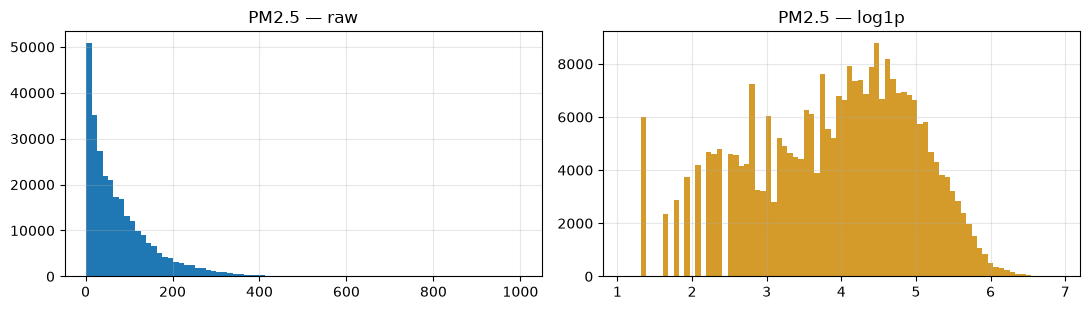

In [18]:
from sklearn.preprocessing import PowerTransformer
vals = train_raw[["PM2.5", "SO2", "CO", "NO2", "O3", "WSPM"]].dropna()
print("skewness raw:\n", vals.skew().round(2))
print("\nskewness after log1p:\n", np.log1p(vals).skew().round(2))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].hist(vals["PM2.5"], bins=80); ax[0].set_title("PM2.5 — raw")
ax[1].hist(np.log1p(vals["PM2.5"]), bins=80, color="#d49a2a"); ax[1].set_title("PM2.5 — log1p")
plt.tight_layout(); plt.show()

## A9 · Multicollinearity — VIF  *(slide 22)*

In [19]:
def vif(frame):
    X = (frame - frame.mean()) / frame.std()
    out = {}
    for c in X.columns:
        Aa = np.column_stack([np.ones(len(X)), X.drop(columns=c).values])
        coef, *_ = np.linalg.lstsq(Aa, X[c].values, rcond=None)
        resid = X[c].values - Aa @ coef
        out[c] = 1 / max(1 - (1 - (resid ** 2).sum() / ((X[c] - X[c].mean()) ** 2).sum()), 1e-12)
    return pd.Series(out, name="VIF").sort_values(ascending=False).round(2)

vif(train_raw[["SO2", "NO2", "CO", "O3", "TEMP", "PRES", "DEWP", "WSPM"]].dropna().sample(50_000, random_state=0))

TEMP    7.83
DEWP    5.75
PRES    3.14
NO2     2.62
CO      2.52
O3      2.23
SO2     1.83
WSPM    1.60
Name: VIF, dtype: float64

## A10 · Leakage demo — random split vs time split  *(slides 27 & 28)*
Same model, same data, two ways of splitting. The random split lets near-identical neighbouring hours sit on both sides.

In [20]:
def add_features(d):
    """Model-ready features: datetime, cyclical time, circular wind direction, dew-point depression."""
    d = d.copy()
    d["datetime"] = pd.to_datetime(d[["year", "month", "day", "hour"]], errors="coerce")
    d["hour_sin"], d["hour_cos"] = np.sin(2 * np.pi * d["hour"] / 24), np.cos(2 * np.pi * d["hour"] / 24)
    d["month_sin"], d["month_cos"] = np.sin(2 * np.pi * d["month"] / 12), np.cos(2 * np.pi * d["month"] / 12)
    d["dow"] = d["datetime"].dt.dayofweek
    ang = d["wd"].map({w: i * 2 * np.pi / 16 for i, w in enumerate(WD)})
    d["wd_sin"], d["wd_cos"] = np.sin(ang), np.cos(ang)
    d["TD_dep"] = d["TEMP"] - d["DEWP"]                      # dew-point depression (humidity)
    d["rain_flag"] = (d["RAIN"] > 0).astype(float).where(d["RAIN"].notna())
    return d

# Virtual PM2.5 sensor: PM10 is deliberately EXCLUDED (same instrument -> down at the same time)
NUM_FEATS = ["SO2", "NO2", "CO", "O3", "TEMP", "PRES", "DEWP", "RAIN", "WSPM", "TD_dep", "rain_flag",
             "hour_sin", "hour_cos", "month_sin", "month_cos", "dow", "wd_sin", "wd_cos"]
CAT_FEATS = ["station"]
TARGET = "PM2.5"

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import KFold, TimeSeriesSplit, cross_val_score

def make_pipeline(model):
    num = Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)), ("scale", StandardScaler())])
    cat = Pipeline([("impute", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore"))])
    prep = ColumnTransformer([("num", num, NUM_FEATS), ("cat", cat, CAT_FEATS)], sparse_threshold=0)
    return Pipeline([("prep", prep), ("model", model)])

ref = add_features(train_raw.drop(columns=["datetime"])).dropna(subset=[TARGET]).sort_values("datetime")
ref = ref.iloc[::3]                                   # every 3rd hour keeps the demo fast
X_ref, y_ref = ref[NUM_FEATS + CAT_FEATS], ref[TARGET]
hgb = make_pipeline(HistGradientBoostingRegressor(max_iter=200, random_state=0))
for name, cv in [("random KFold", KFold(5, shuffle=True, random_state=0)), ("TimeSeriesSplit", TimeSeriesSplit(5))]:
    s = cross_val_score(hgb, X_ref, y_ref, cv=cv, scoring="neg_root_mean_squared_error")
    print(f"{name:16s} CV RMSE = {-s.mean():6.2f} ± {s.std():.2f} µg/m³")

random KFold     CV RMSE =  29.71 ± 0.19 µg/m³
TimeSeriesSplit  CV RMSE =  42.32 ± 10.22 µg/m³


## A11 · Template: a leak-free, time-aware pipeline  *(slide 29)*
`make_pipeline` above is the template you adapt in Task 5. Everything that *learns* (imputers, scalers, encoders) lives **inside** it, so it is re-fitted in every fold.

---
# Part B · Week-1 Team Challenge — *The Air-Quality Data Challenge*

<div style="border:2px solid #d49a2a;background:#fbf1dc;border-radius:10px;padding:12px 18px;color:#14203a;">
<b style="color:#8f5f0c;font-size:15px;">Scenario</b><br>The city’s environmental agency merged the exports of its <b>12 monitoring stations</b> (1 Mar 2013 – 29 Feb 2016) for an AI project. On top of the real gaps, the merge introduced errors. Your file <code>beijing_merged_team&lt;N&gt;.csv.gz</code> (created in A3) is your team’s version. <br><b>Goal:</b> deliver a documented, leak-free pipeline for a <b>virtual PM2.5 sensor</b> — estimate PM2.5 from gases, weather, time and station, <b>without PM10</b> (same instrument, down at the same time) — and <b>prove with numbers</b> how much your data work improves it on the untouched test year.</div>

| # | Task | Points |
|---|---|---|
| 1 | Data-quality audit (six dimensions, gap lengths, missingness by station) | 15 |
| 2 | Consistency, validity & timeliness fixes | 15 |
| 3 | Imputation study (≥ 3 imputers incl. one time-aware) | 15 |
| 4 | Outliers: stuck sensors & spikes vs real episodes; transformations | 10 |
| 5 | Leak-free pipeline + `TimeSeriesSplit` CV | 15 |
| 6 | Impact study on the test year | 20 |
| ★ | HPC bonus: parallel per-station cleaning | +10 |
|   | 1-page report + 5-min pitch | 10 |

**Rules:** `test_year` only in Task 6 · justify every decision in one line · keep `SEED` fixed · start from `beijing_merged_team<N>.csv.gz`, not from `train_raw`.

**Suggested plan:** Days 1–2 Task 1 · Days 3–4 Tasks 2–5 · Day 5 Task 6 (+ bonus) · Days 6–7 report & pitch.

**Hint — what kinds of problems to look for:** label variants, a unit mix-up, a time-zone shift, re-uploaded data, stuck sensors, sentinel codes, physically impossible values, extra drop-outs. *Which station, which column, which period? That is for you to find.*

## Task 1 · Data-quality audit (15 pts)

In [21]:
df = pd.read_csv(f"beijing_merged_team{TEAM_ID}.csv.gz")
aud = df.copy()
aud["st"] = aud["station"].str.strip().str.title()
aud["dt"] = pd.to_datetime(aud[["year", "month", "day", "hour"]])
aud = aud.sort_values(["st", "dt"]).reset_index(drop=True)


### 1a completeness: % missing per column AND per station; gap-length distribution

In [22]:
COLS = POLLUTANTS + WEATHER + ["wd"]
miss_col = (df[COLS].isna().mean() * 100).round(2).sort_values(ascending=False)
print("% missing per column:\n", miss_col.to_string(), "\n")

miss_st = (aud.groupby("st")[COLS].apply(lambda g: g.isna().mean()) * 100).round(1)
print("% missing per station:")
display(miss_st)

def gap_lengths(s):
    """Lengths of the runs of consecutive NaN in a time-ordered series."""
    isna = s.isna()
    run_id = (isna != isna.shift()).cumsum()
    runs = isna.groupby(run_id).sum()
    return runs[runs > 0]

bins, labels = [0, 1, 3, 24, 10**6], ["1 h", "2-3 h", "4-24 h", "> 24 h"]
gap_table = {}
for c in POLLUTANTS + ["TEMP", "PRES", "WSPM"]:
    L = pd.concat([gap_lengths(g[c]) for _, g in aud.groupby("st")])
    gap_table[c] = pd.cut(L, bins=bins, labels=labels).value_counts().reindex(labels)
gap_table = pd.DataFrame(gap_table).T
print("number of gaps by gap length (all stations):")
display(gap_table)


% missing per column:
 NO2      6.00
CO       5.74
O3       3.22
SO2      2.21
PM2.5    2.02
PM10     1.46
wd       0.21
TEMP     0.06
PRES     0.06
DEWP     0.06
RAIN     0.06
WSPM     0.06 

% missing per station:


,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,WSPM,wd
st,,,,,,,,,,,,
Aotizhongxin,2.8,2.3,3.0,5.8,6.2,5.5,0.0,0.0,0.0,0.0,0.0,0.0
Changping,2.5,1.8,1.9,5.0,5.2,1.9,0.1,0.1,0.1,0.1,0.1,0.3
Dingling,1.9,1.9,2.0,7.0,6.7,2.9,0.1,0.1,0.1,0.1,0.1,0.3
Dongsi,1.4,0.9,1.3,7.9,10.8,1.2,0.0,0.0,0.0,0.0,0.0,0.0
Guanyuan,1.6,1.1,1.4,4.9,5.8,4.0,0.0,0.0,0.0,0.0,0.0,0.0
Gucheng,1.9,1.1,1.6,5.1,4.9,2.4,0.1,0.1,0.1,0.1,0.1,0.5
Huairou,3.1,2.5,3.2,7.8,4.6,3.7,0.1,0.1,0.1,0.1,0.1,0.5
Nongzhanguan,1.8,1.3,1.3,5.1,3.7,1.4,0.0,0.0,0.0,0.0,0.0,0.0
Shunyi,2.2,1.1,3.3,6.3,6.7,2.2,0.1,0.1,0.1,0.1,0.1,0.8


number of gaps by gap length (all stations):


,1 h,2-3 h,4-24 h,> 24 h
PM2.5,1087,560,249,28
PM10,978,328,195,18
SO2,1317,427,232,36
NO2,10097,961,320,37
CO,2490,730,467,62
O3,2284,605,399,39
TEMP,148,11,1,0
PRES,150,11,1,0
WSPM,151,13,0,0


### 1b uniqueness: duplicate station-hours (KEY); are duplicates identical or slightly different?

In [23]:

key_c = ["st", "year", "month", "day", "hour"]
dup_key = aud.duplicated(subset=key_c, keep=False)
dup_exact = aud.duplicated(subset=key_c + POLLUTANTS + WEATHER + ["wd"], keep=False)
print(f"uniqueness = distinct keys / rows = {aud[key_c].drop_duplicates().shape[0] / len(aud):.4f}")
print(f"extra rows on a duplicated station-hour : {aud.duplicated(subset=key_c).sum():,}")
print(f"  of which exact copies                  : {aud.duplicated(subset=key_c + POLLUTANTS + WEATHER + ['wd']).sum():,}")
print("\nduplicated station-hours that are NOT identical, by station / year / month:")
diff = aud[dup_key & ~dup_exact]
display(diff.groupby(["st", "year", "month"]).size().rename("rows"))


g = diff.groupby(key_c)
differs = {c: int((g[c].nunique() > 1).sum()) for c in POLLUTANTS + WEATHER}
print("number of non-identical pairs where the column differs:", {k: v for k, v in differs.items() if v > 0})
ex = diff[diff["st"] == diff.groupby("st").size().idxmax()].sort_values(key_c).head(4)
display(ex[["No", "st", "year", "month", "day", "hour", "PM2.5", "NO2", "O3", "TEMP"]])

uniqueness = distinct keys / rows = 0.9927
extra rows on a duplicated station-hour : 2,306
  of which exact copies                  : 1,580

duplicated station-hours that are NOT identical, by station / year / month:


st            year  month
Huairou       2014  12         16
Nongzhanguan  2014  9        1431
Name: rows, dtype: int64

number of non-identical pairs where the column differs: {'PM2.5': 7, 'PM10': 7, 'SO2': 5, 'NO2': 7, 'CO': 6, 'O3': 720, 'TEMP': 8, 'PRES': 8, 'DEWP': 8, 'WSPM': 8}


,No,st,year,month,day,hour,PM2.5,NO2,O3,TEMP
198294,13177,Nongzhanguan,2014,9,1,0,74.0,74.0,9.0,20.7
198295,13177,Nongzhanguan,2014,9,1,0,74.0,74.0,10.0,20.7
198296,13178,Nongzhanguan,2014,9,1,1,70.0,71.0,10.0,21.1
198297,13178,Nongzhanguan,2014,9,1,1,70.0,71.0,11.0,21.1


### 1c validity: PM2.5 > PM10, negative values, -999 codes, implausible PRES / TEMP

In [24]:
# ---- 1c VALIDITY ----
validity = {
    "PM2.5 > PM10 (part > total)":  int((aud["PM2.5"] > aud["PM10"]).sum()),
    "negative concentrations":      int((aud[POLLUTANTS] < 0).sum().sum()),
    "TEMP == -999":                 int((aud["TEMP"] == -999).sum()),
    "PRES == -999":                 int((aud["PRES"] == -999).sum()),
    "-999 in other columns":        int((aud[POLLUTANTS + ["DEWP", "RAIN", "WSPM"]] == -999).sum().sum()),
    "PRES outside 950-1060 hPa (excl. -999)": int((((aud["PRES"] < 950) | (aud["PRES"] > 1060)) & (aud["PRES"] != -999)).sum()),
    "TEMP outside -40..45 C (excl. -999)":    int((((aud["TEMP"] < -40) | (aud["TEMP"] > 45)) & (aud["TEMP"] != -999)).sum()),
}
display(pd.Series(validity, name="rows"))

aud_u = aud.drop_duplicates(subset=key_c)




PM2.5 > PM10 (part > total)               22027
negative concentrations                       0
TEMP == -999                                638
PRES == -999                                637
-999 in other columns                         0
PRES outside 950-1060 hPa (excl. -999)        0
TEMP outside -40..45 C (excl. -999)           0
Name: rows, dtype: int64

### 1d accuracy: station medians of each pollutant on a log scale — any station x1000 off? which years?

In [25]:
# 1. Median of each pollutant for each station and year
med = aud.groupby(["st", "year"])[POLLUTANTS].median()

reference = med.groupby(level="year").transform("median")
ratio_log10 = np.log10(
    med.where(med > 0) / reference.where(reference > 0)
)

# 3. Display station-year medians
for pollutant in POLLUTANTS:
    print(f"\n{pollutant} — median by station and year:")
    display(med[pollutant].unstack("year").round(2))



PM2.5 — median by station and year:


year,2013,2014,2015,2016
st,,,,
Aotizhongxin,62.0,69.0,56.0,21.0
Changping,52.0,53.0,45.0,19.0
Dingling,43.0,47.0,39.0,16.0
Dongsi,66.0,66.0,58.0,22.0
Guanyuan,62.0,67.0,56.0,22.0
Gucheng,62.0,68.0,56.0,30.0
Huairou,48.0,54.0,46.0,23.0
Nongzhanguan,63.0,65.0,56.0,22.0
Shunyi,57.0,62.0,53.0,22.0



PM10 — median by station and year:


year,2013,2014,2015,2016
st,,,,
Aotizhongxin,97.0,98.0,87.0,44.0
Changping,74.0,85.0,68.0,44.0
Dingling,58.0,68.0,59.0,39.0
Dongsi,91.0,96.0,85.0,47.0
Guanyuan,93.0,97.0,83.0,44.0
Gucheng,100.0,118.0,91.0,55.0
Huairou,74.0,81.0,65.0,35.0
Nongzhanguan,87.0,102.0,81.0,39.0
Shunyi,80.0,92.0,74.0,33.0



SO2 — median by station and year:


...

year,2013,2014,2015,2016
st,,,,
Aotizhongxin,60.00,60.0,53.0,34.0
Changping,35.00,38.0,34.0,42.0
Dingling,22.00,19.0,19.0,10.0
Dongsi,52.00,51.0,42.0,35.0
Guanyuan,53.00,58.0,46.0,44.0
Gucheng,58.00,58.0,43.0,32.0
Huairou,30.00,31.0,21.0,21.0
Nongzhanguan,54.00,57.0,48.0,43.0
Shunyi,35.00,40.0,37.0,29.0



CO — median by station and year:


year,2013,2014,2015,2016
st,,,,
Aotizhongxin,900.0,900.0,900.0,800.0
Changping,800.0,0.8,700.0,700.0
Dingling,700.0,600.0,600.0,400.0
Dongsi,1100.0,1100.0,900.0,700.0
Guanyuan,900.0,1000.0,900.0,800.0
Gucheng,1000.0,1000.0,900.0,1000.0
Huairou,800.0,900.0,700.0,700.0
Nongzhanguan,1000.0,1000.0,900.0,700.0
Shunyi,1000.0,900.0,800.0,600.0



O3 — median by station and year:


year,2013,2014,2015,2016
st,,,,
Aotizhongxin,34.00,32.0,50.0,46.0
Changping,48.00,50.0,47.0,43.0
Dingling,56.00,63.0,65.0,66.0
Dongsi,47.00,44.0,43.0,40.0
Guanyuan,44.00,39.0,41.0,31.0
Gucheng,45.00,44.0,48.0,44.0
Huairou,51.00,57.0,49.0,29.0
Nongzhanguan,42.00,43.0,47.0,44.0
Shunyi,46.00,43.0,39.0,42.0


### 1e timeliness: hour of the mean daily TEMP / O3 peak per station and year — any station shifted?

In [26]:

med = aud.groupby(["st", "year"])[POLLUTANTS].median()
reference = med.groupby(level="year").transform("median")
ratio_log10 = np.log10(
    med.where(med > 0) / reference.where(reference > 0)
)


for pollutant in POLLUTANTS:
    print(f"\n{pollutant} — median by station and year:")
    display(med[pollutant].unstack("year").round(2))

flags = ratio_log10.stack().rename("log10_ratio").reset_index()
flags = flags[flags["log10_ratio"].abs() >= 2.5]

print("\nPotential station-year scale anomalies (approximately x300 or more):")
if flags.empty:
    print("No potential large scale anomalies detected.")
else:
    display(flags.sort_values("log10_ratio", key=lambda s: s.abs(),
                              ascending=False))



PM2.5 — median by station and year:


year,2013,2014,2015,2016
st,,,,
Aotizhongxin,62.0,69.0,56.0,21.0
Changping,52.0,53.0,45.0,19.0
Dingling,43.0,47.0,39.0,16.0
Dongsi,66.0,66.0,58.0,22.0
Guanyuan,62.0,67.0,56.0,22.0
Gucheng,62.0,68.0,56.0,30.0
Huairou,48.0,54.0,46.0,23.0
Nongzhanguan,63.0,65.0,56.0,22.0
Shunyi,57.0,62.0,53.0,22.0



PM10 — median by station and year:


year,2013,2014,2015,2016
st,,,,
Aotizhongxin,97.0,98.0,87.0,44.0
Changping,74.0,85.0,68.0,44.0
Dingling,58.0,68.0,59.0,39.0
Dongsi,91.0,96.0,85.0,47.0
Guanyuan,93.0,97.0,83.0,44.0
Gucheng,100.0,118.0,91.0,55.0
Huairou,74.0,81.0,65.0,35.0
Nongzhanguan,87.0,102.0,81.0,39.0
Shunyi,80.0,92.0,74.0,33.0



SO2 — median by station and year:


...

year,2013,2014,2015,2016
st,,,,
Aotizhongxin,900.0,900.0,900.0,800.0
Changping,800.0,0.8,700.0,700.0
Dingling,700.0,600.0,600.0,400.0
Dongsi,1100.0,1100.0,900.0,700.0
Guanyuan,900.0,1000.0,900.0,800.0
Gucheng,1000.0,1000.0,900.0,1000.0
Huairou,800.0,900.0,700.0,700.0
Nongzhanguan,1000.0,1000.0,900.0,700.0
Shunyi,1000.0,900.0,800.0,600.0



O3 — median by station and year:


year,2013,2014,2015,2016
st,,,,
Aotizhongxin,34.00,32.0,50.0,46.0
Changping,48.00,50.0,47.0,43.0
Dingling,56.00,63.0,65.0,66.0
Dongsi,47.00,44.0,43.0,40.0
Guanyuan,44.00,39.0,41.0,31.0
Gucheng,45.00,44.0,48.0,44.0
Huairou,51.00,57.0,49.0,29.0
Nongzhanguan,42.00,43.0,47.0,44.0
Shunyi,46.00,43.0,39.0,42.0



Potential station-year scale anomalies (approximately x300 or more):


,st,year,level_2,log10_ratio
34,Changping,2014,CO,-3.074634


### 1f consistency: raw station and wd labels

In [27]:
print(f"distinct station labels: {df['station'].nunique()} (expected 12)")
print(df["station"].value_counts().to_string(), "\n")
wd_raw = sorted(df["wd"].dropna().unique())
print(f"distinct wd labels: {len(wd_raw)} (expected 16):", wd_raw)
print("rows with a non-canonical station label:", int((~df["station"].isin(STATIONS)).sum()))
print("rows with a lower-case wd label       :", int((df["wd"].notna() & ~df["wd"].isin(WD)).sum()))

distinct station labels: 36 (expected 12)
station
Nongzhanguan      24451
Shunyi            23871
Aotizhongxin      23842
Changping         23841
Guanyuan          23815
Tiantan           23795
Huairou           23780
Dingling          23776
Dongsi            23773
Wanshouxigong     23730
Wanliu            23725
Gucheng           23723
gucheng            1406
nongzhanguan       1382
wanliu             1379
WANSHOUXIGONG      1347
tiantan            1346
DINGLING           1342
wanshouxigong      1339
WANLIU             1331
huairou            1331
DONGSI             1330
dingling           1329
NONGZHANGUAN       1328
changping          1326
HUAIROU            1322
AOTIZHONGXIN       1319
guanyuan           1318
GUANYUAN           1315
dongsi             1311
TIANTAN            1309
GUCHENG            1302
SHUNYI             1280
shunyi             1279
CHANGPING          1279
aotizhongxin       1274 

distinct wd labels: 32 (expected 16): ['E', 'ENE', 'ESE', 'N', 'NE', 'NNE', 'NNW', '

In [28]:
issue_log = pd.DataFrame(columns=["dimension", "station", "column", "period", "problem", "rows affected", "fix", "justification"])
def log(*row): issue_log.loc[len(issue_log)] = list(row)
START = pd.Timestamp("2013-03-01 00:00")
true_dt = START + pd.to_timedelta(aud["No"] - 1, unit="h")         
lag = (true_dt - aud["dt"]).dt.total_seconds() / 3600             

tmp = aud.assign(TEMP=aud["TEMP"].mask(aud["TEMP"] == -999))
prof = tmp.groupby(["st", "year", "hour"])[["TEMP", "O3"]].mean()
peak = prof.groupby(["st", "year"]).idxmax().apply(lambda col: col.map(lambda t: t[-1]))
def stuck_runs(s, min_len=12):
    """True for values that sit inside a run of >= min_len identical consecutive values."""
    run_id = (s != s.shift()).cumsum()
    run_len = s.groupby(run_id).transform("size")
    return (run_len >= min_len) & s.notna()

stuck = {st: int(stuck_runs(g["PM2.5"]).sum()) for st, g in aud.groupby("st")}

n_lab = int((~df["station"].isin(STATIONS)).sum()); n_wd = int((df["wd"].notna() & ~df["wd"].isin(WD)).sum())
n_co = int(((aud["st"] == "Changping") & (aud["year"] == 2014)).sum())
n_tz = int((lag == 8).sum())
n_dup_exact = int(aud.duplicated(subset=key_c + POLLUTANTS + WEATHER + ["wd"]).sum())
n_reup = int(((diff["st"] == "Nongzhanguan")).sum() // 2)
n_stuck = int(sum(stuck.values()))
n_swap = validity["PM2.5 > PM10 (part > total)"]

log("consistency", "all", "station", "all", "36 label variants (UPPER, lower + trailing space)", n_lab, "strip + title-case", "same station, different spelling")
log("consistency", "all", "wd", "all", "lower-case compass points", n_wd, "upper-case", "16 canonical directions")
log("accuracy", "Changping", "CO", "2014", "CO in mg/m³ (median 0.8 vs ~900)", n_co, "x 1000", "station-year median 1000x below others")
log("timeliness", "Huairou", "year/month/day/hour", "2015", "exported in UTC: O3/TEMP peak 8 h early", n_tz, "+8 h (rows found with the 'No' counter)", "diurnal profile + row counter agree")
log("uniqueness", "all", "all", "all", "exact duplicate rows", n_dup_exact, "keep one", "same record stored twice")
log("uniqueness", "Nongzhanguan", "O3", "2014-09", "month re-uploaded, O3 differs by 1", n_reup, "keep first copy", "difference 1 µg/m³, negligible")
log("validity", "all", "TEMP", "all", "-999 sentinel", validity["TEMP == -999"], "set to NaN", "not a measurement")
log("validity", "all", "PRES", "all", "-999 sentinel", validity["PRES == -999"], "set to NaN", "not a measurement")
log("validity", "all", "PM2.5/PM10", "all", "PM2.5 > PM10 (part > total)", n_swap, "swap so PM2.5 = smaller value", "PM2.5 is a part of PM10")
log("validity", "Aotizhongxin (+5 others)", "PM2.5", "all", "flat runs >= 12 h (stuck sensor)", n_stuck, "set to NaN", "a real PM2.5 signal always varies")
log("completeness", "all", "NO2", "all", "extra single-hour drop-outs (6 % missing, 10k 1-h gaps)", int(df["NO2"].isna().sum()), "impute (Task 3)", "looks MCAR: other variables similar when NO2 missing")
issue_log

,dimension,station,column,period,problem,rows affected,fix,justification
0,consistency,all,station,all,"36 label variants (UPPER, lower + trailing space)",31824,strip + title-case,"same station, different spelling"
1,consistency,all,wd,all,lower-case compass points,6422,upper-case,16 canonical directions
2,accuracy,Changping,CO,2014,CO in mg/m³ (median 0.8 vs ~900),8810,x 1000,station-year median 1000x below others
3,timeliness,Huairou,year/month/day/hour,2015,exported in UTC: O3/TEMP peak 8 h early,8802,+8 h (rows found with the 'No' counter),diurnal profile + row counter agree
4,uniqueness,all,all,all,exact duplicate rows,1580,keep one,same record stored twice
5,uniqueness,Nongzhanguan,O3,2014-09,"month re-uploaded, O3 differs by 1",715,keep first copy,"difference 1 µg/m³, negligible"
6,validity,all,TEMP,all,-999 sentinel,638,set to NaN,not a measurement
7,validity,all,PRES,all,-999 sentinel,637,set to NaN,not a measurement
8,validity,all,PM2.5/PM10,all,PM2.5 > PM10 (part > total),22027,swap so PM2.5 = smaller value,PM2.5 is a part of PM10
9,validity,Aotizhongxin (+5 others),PM2.5,all,flat runs >= 12 h (stuck sensor),668,set to NaN,a real PM2.5 signal always varies


## Task 2 · Consistency, validity & timeliness fixes (15 pts)
Write **one function** `clean_basic(df)` you could apply to next month's export. It should at least: canonicalise `station` and `wd`; fix the unit problem; undo the time-zone shift; set sentinel codes and impossible values to NaN (or repair the swap); flag stuck-sensor runs as NaN; resolve duplicate station-hours; build `datetime`; sort by station and time.

In [29]:
START = pd.Timestamp("2013-03-01 00:00")      

def stuck_runs(s, min_len=12):
    """True for values that sit inside a run of >= min_len identical consecutive values."""
    run_id = (s != s.shift()).cumsum()
    run_len = s.groupby(run_id).transform("size")
    return (run_len >= min_len) & s.notna()

def clean_basic(d):
    d = d.copy()
    # 1) consistency: canonical labels
    d["station"] = d["station"].str.strip().str.title()
    d["wd"] = d["wd"].str.strip().str.upper()
    # 2) accuracy: CO in µg/m³ is never below ~100; a station-year median < 50 means the export used mg/m³
    co_med = d.groupby(["station", "year"])["CO"].transform("median")
    d.loc[co_med < 50, "CO"] = d.loc[co_med < 50, "CO"] * 1000
    # 3) timeliness: the 'No' row counter gives the true local hour; rows 8 h behind it were exported in UTC
    dt = pd.to_datetime(d[["year", "month", "day", "hour"]])
    true_dt = START + pd.to_timedelta(d["No"] - 1, unit="h")
    utc = (true_dt - dt) == pd.Timedelta(hours=8)
    dt[utc] = dt[utc] + pd.Timedelta(hours=8)
    d["year"], d["month"], d["day"], d["hour"] = dt.dt.year, dt.dt.month, dt.dt.day, dt.dt.hour
    # 4) validity: sentinel codes -> NaN ; impossible values -> NaN ; PM2.5 > PM10 -> swap back
    num_cols = POLLUTANTS + WEATHER
    d[num_cols] = d[num_cols].mask(d[num_cols] == -999)
    d[POLLUTANTS] = d[POLLUTANTS].mask(d[POLLUTANTS] < 0)
    d.loc[(d["PRES"] < 950) | (d["PRES"] > 1060), "PRES"] = np.nan
    d.loc[(d["TEMP"] < -40) | (d["TEMP"] > 45), "TEMP"] = np.nan
    sw = d["PM2.5"] > d["PM10"]
    d.loc[sw, ["PM2.5", "PM10"]] = d.loc[sw, ["PM10", "PM2.5"]].values
    # 5) uniqueness: one row per station-hour (keep the first copy) — done AFTER the time-zone fix
    d = d.drop_duplicates(subset=KEY, keep="first")
    # 6) stuck sensor: flat PM2.5 runs >= 12 h -> NaN (done after removing duplicates, which also look flat)
    d["datetime"] = pd.to_datetime(d[["year", "month", "day", "hour"]], errors="coerce")
    d = d.sort_values(["station", "datetime"]).reset_index(drop=True)
    flat = d.groupby("station")["PM2.5"].transform(stuck_runs)
    d.loc[flat, "PM2.5"] = np.nan
    return d

df_clean = clean_basic(df)
print(f"{len(df):,} -> {len(df_clean):,} rows | stations: {df_clean['station'].nunique()}")

317,946 -> 315,648 rows | stations: 12


## Task 3 · Imputation study (15 pts)
Using **your cleaned data**, extend A7: compare ≥ 3 imputers (at least one time-aware, e.g. limited interpolation, neighbour-station, seasonal-hourly profile) for **two** pollutants, with both single-hour and 24-h masks. Choose a strategy per gap length and justify it.

In [30]:
from sklearn.impute import KNNImputer

rng = np.random.default_rng(SEED)

def imputation_study(pollutant, target_st):
    # Use cleaned data
    piv = (
        df_clean.pivot_table(
            index="datetime",
            columns="station",
            values=pollutant
        ).sort_index()
    )

    truth = piv[target_st]
    known = np.flatnonzero(truth.notna().values)
    others = piv.drop(columns=target_st)
    nb = others.mean(axis=1)

    def make_mask(kind):
        m = np.zeros(len(truth), dtype=bool)

        if kind == "single hours":
            m[rng.choice(known, len(known) // 10, replace=False)] = True

        else:  # 24 consecutive hours
            valid_starts = [
                i for i in range(len(truth) - 23)
                if truth.iloc[i:i + 24].notna().all()
            ]
            starts = rng.choice(
                valid_starts,
                min(150, len(valid_starts)),
                replace=False
            )
            for s0 in starts:
                m[s0:s0 + 24] = True

        return m

    def evaluate(mask):
        s = truth.mask(mask)

        # Median by month and hour
        profile = s.groupby(
            [s.index.month, s.index.hour]
        ).transform("median")

        cand = {
            "mean": s.fillna(s.mean()),
            "median": s.fillna(s.median()),
            "time interpolation": s.interpolate(
                method="time", limit=24
            ),
            "seasonal-hourly profile": s.fillna(profile),
            "neighbour stations": s.fillna(
                nb + (s - nb).mean()
            ),
            "KNN across stations": pd.Series(
                KNNImputer(n_neighbors=5).fit_transform(
                    piv.assign(**{target_st: s})
                )[:, list(piv.columns).index(target_st)],
                index=s.index
            ),
        }

        return {
            method: np.sqrt(np.mean(
                (values.fillna(s.mean()).values[mask]
                 - truth.values[mask]) ** 2
            ))
            for method, values in cand.items()
        }

    return pd.DataFrame({
        kind: evaluate(make_mask(kind))
        for kind in ["single hours", "24-h blocks"]
    })


t0 = time.perf_counter()

study = pd.concat(
    {
        "PM2.5": imputation_study("PM2.5", "Dongsi"),
        "NO2": imputation_study("NO2", "Dongsi"),
    },
    axis=1
).round(2)

print(
    f"({time.perf_counter() - t0:.1f} s) "
    "RMSE in µg/m³ — lower is better"
)
display(study)

(206.5 s) RMSE in µg/m³ — lower is better


PM2.5                      NO2            
                        single hours 24-h blocks single hours 24-h blocks
mean                           85.06       86.35        33.84       34.69
median                         88.15       90.70        34.10       35.15
time interpolation             14.43       59.86         7.94       28.55
seasonal-hourly profile        88.07       89.20        31.64       32.35
neighbour stations             24.81       23.69        14.37       13.42
KNN across stations            16.39       17.81        10.33       10.04

In [31]:
from sklearn.impute import KNNImputer

# Decision from the study:  gaps <= 3 h -> time interpolation ;  longer gaps -> KNN across stations
# The target PM2.5 is NOT imputed (we only learn from real measurements). Anything left -> median + indicator in the pipeline.
FILL_COLS = ["SO2", "NO2", "CO", "O3", "TEMP", "PRES", "DEWP", "RAIN", "WSPM"]

def gap_len(s):
    """For each NaN: the length of the gap it belongs to (0 for observed values)."""
    isna = s.isna()
    run_id = (isna != isna.shift()).cumsum()
    return isna.groupby(run_id).transform("sum").where(isna, 0)

def fill_short_gaps(g):
    """Step 1, per station: time interpolation for gaps of 1-3 h only."""
    g = g.set_index("datetime").copy()
    for c in FILL_COLS:
        L = gap_len(g[c])
        interp = g[c].interpolate(method="time", limit_area="inside")
        g[c] = g[c].where(~((L > 0) & (L <= 3)), interp)
    return g.reset_index()

def fill_long_gaps_knn(df, k=5):
    """Step 2, per column: KNN across stations (hours x stations table)."""
    df = df.set_index(["datetime", "station"]).copy()
    for c in FILL_COLS:
        piv = df[c].unstack("station")                                   
        imp = pd.DataFrame(KNNImputer(n_neighbors=k).fit_transform(piv),
                           index=piv.index, columns=piv.columns)
        df[c] = df[c].fillna(imp.stack().reindex(df.index))              
    return df.reset_index()

df_short = pd.concat([fill_short_gaps(g) for _, g in df_clean.groupby("station")], ignore_index=True)
df_imp = fill_long_gaps_knn(df_short)
df_imp["RAIN"] = df_imp["RAIN"].clip(lower=0)

print("% missing before -> after imputation:")
pd.DataFrame({"before": df_clean[FILL_COLS].isna().mean() * 100,
              "after": df_imp[FILL_COLS].isna().mean() * 100}).round(2).T

% missing before -> after imputation:


,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,WSPM
before,2.21,5.98,5.74,3.22,0.26,0.26,0.06,0.06,0.06
after,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00


For single-hour gaps I use time interpolation, which has the lowest RMSE for both PM2.5 (14.43) and NO2 (7.94), because the adjacent hours are available and pollutant concentrations change smoothly from one hour to the next. For 24-hour blocks I use KNN across stations, which gives the lowest RMSE (PM2.5 17.81, NO2 10.04), because interpolation degrades sharply (59.86 and 28.55) once the neighbouring hours are missing. KNN keeps its accuracy because it borrows information from the other stations at the same hours, which captures the day’s weather and pollution episode. Mean, median and seasonal-hourly profiles are not competitive in either case, since they ignore the local context.

## Task 4 · Outliers & transformations (10 pts)
Classify flagged points as **error** (stuck, impossible, code) vs **real episode** (e.g. Spring Festival fireworks, winter smog). Show at least one example of each on a time plot. Report skewness before/after your transform.

In [32]:
spk = []
for st, g in df_clean.groupby("station"):
    f = hampel_flags(g["PM2.5"])
    spk.append(g.loc[f, ["station", "datetime", "PM2.5"]])
spk = pd.concat(spk)
others_med = df_clean.pivot_table(index="datetime", columns="station", values="PM2.5")
spk["others_median"] = [others_med.loc[t].drop(s).median() for s, t in zip(spk["station"], spk["datetime"])]
spk["ratio"] = spk["PM2.5"] / spk["others_median"]
spk["type"] = np.where(spk["ratio"] < 3, "regional (real episode)", "isolated (check)")
print(f"Hampel spikes on cleaned PM2.5: {len(spk):,}")
display(spk["type"].value_counts())
print("month of the spikes (winter = heating season):")
display(spk["datetime"].dt.month.value_counts().sort_index().rename("spikes").to_frame().T)

Hampel spikes on cleaned PM2.5: 14,217


type
regional (real episode)    13646
isolated (check)             571
Name: count, dtype: int64

month of the spikes (winter = heating season):


datetime,1,2,3,4,5,6,7,8,9,10,11,12
spikes,1509,1472,1441,1057,1142,871,759,897,884,1073,1408,1704


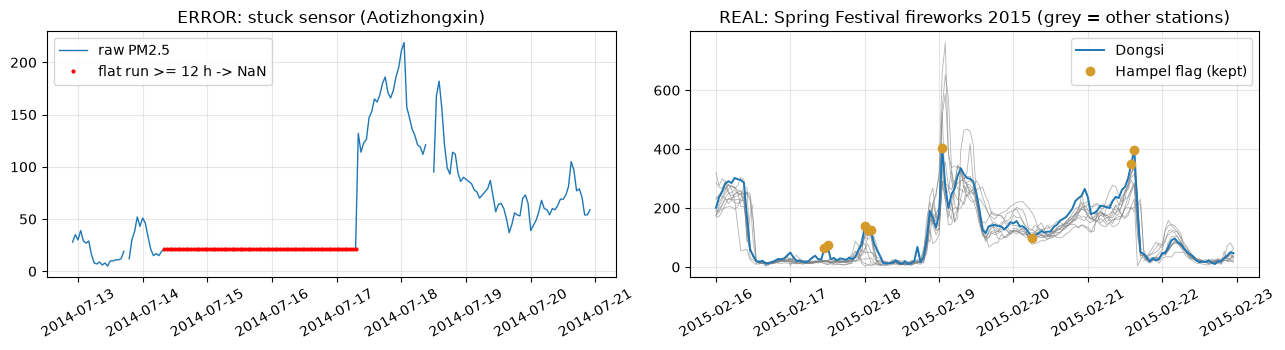

In [33]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))

raw_a = aud_u[aud_u["st"] == "Aotizhongxin"].set_index("dt")["PM2.5"]
fl = stuck_runs(raw_a)
t_mid = fl[fl].index[len(fl[fl]) // 2]
w = raw_a[t_mid - pd.Timedelta("4D"): t_mid + pd.Timedelta("4D")]
ax[0].plot(w.index, w.values, lw=1, label="raw PM2.5")
ax[0].plot(w[fl.reindex(w.index)].index, w[fl.reindex(w.index)].values, "r.", ms=4, label="flat run >= 12 h -> NaN")
ax[0].set_title("ERROR: stuck sensor (Aotizhongxin)"); ax[0].legend(); ax[0].tick_params(axis="x", rotation=30)



w2 = others_med["2015-02-16":"2015-02-22"]
ax[1].plot(w2.index, w2.values, lw=.6, color="grey", alpha=.6)
ax[1].plot(w2.index, w2["Dongsi"], lw=1.4, color="C0", label="Dongsi")
s2 = spk[(spk["station"] == "Dongsi") & (spk["datetime"].between("2015-02-16", "2015-02-22"))]
ax[1].plot(s2["datetime"], s2["PM2.5"], "o", color="#d49a2a", label="Hampel flag (kept)")
ax[1].set_title("REAL: Spring Festival fireworks 2015 (grey = other stations)"); ax[1].legend(); ax[1].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

,raw,log1p
PM2.5,1.96,-0.32
SO2,2.74,0.42
NO2,1.03,-0.72
CO,2.45,-0.00
O3,1.76,-0.58
WSPM,1.67,0.29


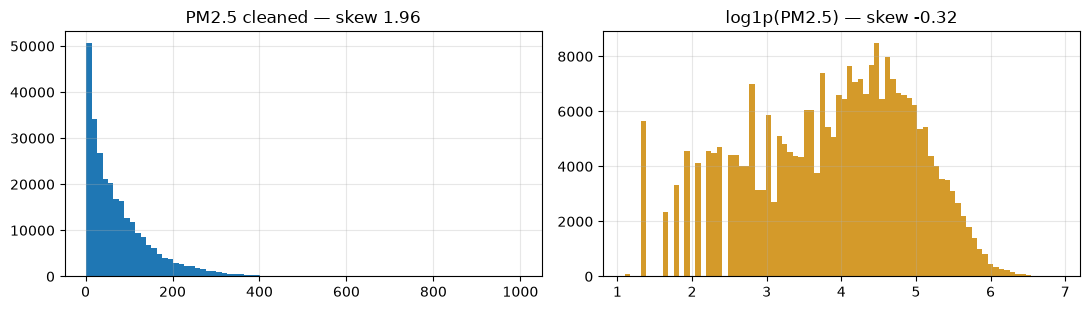

In [34]:
# ---- Transformations: skewness before / after log1p ----
cols4 = ["PM2.5", "SO2", "NO2", "CO", "O3", "WSPM"]
v4 = df_clean[cols4].dropna()
skew_tab = pd.DataFrame({"raw": v4.skew(), "log1p": np.log1p(v4).skew()}).round(2)
display(skew_tab)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].hist(v4["PM2.5"], bins=80); ax[0].set_title(f"PM2.5 cleaned — skew {skew_tab.loc['PM2.5','raw']}")
ax[1].hist(np.log1p(v4["PM2.5"]), bins=80, color="#d49a2a"); ax[1].set_title(f"log1p(PM2.5) — skew {skew_tab.loc['PM2.5','log1p']}")
plt.tight_layout(); plt.show()

###  conclusion — Task 4

- **Errors** were already removed in Task 2: stuck runs (example plotted: a flat line at Aotizhongxin), -999 codes and PM2.5/PM10 swaps. All three are physically impossible.
- **Hampel spikes** on the cleaned PM2.5: 14,217 flags. **13,646 (96 %) are regional**, meaning the other stations are high at the same hour (ratio < 3). Only 571 are isolated. They are most frequent in Dec/Jan (1,704 / 1,509), which is the heating season.
- **Real episode example:** the Spring Festival fireworks on the night of 18–19 Feb 2015. Every station rises at the same time, so it is real data, and we **keep** it.
- **Policy:** physically impossible values → NaN. Plausible extremes are kept, because they are exactly what the public needs predicted. Isolated spikes are kept too, because nothing proves they are wrong.
- **Skewness before → after log1p:** PM2.5 1.96 → −0.32, SO2 2.74 → 0.42, CO 2.45 → 0.00, NO2 1.03 → −0.72, O3 1.76 → −0.58, WSPM 1.67 → 0.29. Trees are not affected by transforming features, so the log is only tested on the **target**, in Task 5.

**Conclusion:** most outliers are real smog episodes, not errors. We remove errors and keep extremes.

## Task 5 · Leak-free pipeline + TimeSeriesSplit CV (15 pts)
Use `add_features` and adapt `make_pipeline` (A10). Report 5-fold `TimeSeriesSplit` RMSE ± sd for the virtual sensor on `df_clean` (sorted by `datetime`). Try at least two preprocessing variants (e.g. with/without missing indicators, log-target via `TransformedTargetRegressor`).

In [35]:
from sklearn.compose import TransformedTargetRegressor

def make_pipeline(model, indicator=True):
    num = Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=indicator)),
                    ("scale", StandardScaler())])
    cat = Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                    ("onehot", OneHotEncoder(handle_unknown="ignore"))])
    prep = ColumnTransformer([("num", num, NUM_FEATS), ("cat", cat, CAT_FEATS)], sparse_threshold=0)
    return Pipeline([("prep", prep), ("model", model)])

def prepare(df):
    d = (add_features(df.drop(columns=["datetime"]))
         .dropna(subset=[TARGET])
         .sort_values(["datetime", "station"]))          # same row order for every variant
    return d[NUM_FEATS + CAT_FEATS], d[TARGET]

X5, y5   = prepare(df_clean)
X5i, y5i = prepare(df_imp)
assert len(X5) == len(X5i), "cleaned and imputed tables must have the same rows"

def new_hgb(): return HistGradientBoostingRegressor(max_iter=200, random_state=0)
def log_target(m): return TransformedTargetRegressor(regressor=m, func=np.log1p, inverse_func=np.expm1)

variants = {
    "V1 cleaned, median + indicator":        (make_pipeline(new_hgb(), indicator=True),  X5,  y5),
    "V2 cleaned, median, NO indicator":      (make_pipeline(new_hgb(), indicator=False), X5,  y5),
    "V3 imputed (interp/KNN)":               (make_pipeline(new_hgb(), indicator=False), X5i, y5i),
    "V4 imputed + log1p target":             (log_target(make_pipeline(new_hgb(), indicator=False)), X5i, y5i),
    "V5 cleaned + indicator + log1p target": (log_target(make_pipeline(new_hgb(), indicator=True)),  X5,  y5),
}

cv5 = TimeSeriesSplit(5)
rows5 = {}
for name, (model, X, y) in variants.items():
    t0 = time.perf_counter()
    s = -cross_val_score(model, X, y, cv=cv5, scoring="neg_root_mean_squared_error", n_jobs=-1)
    rows5[name] = {"CV RMSE": s.mean(), "± sd": s.std(),
                   **{f"fold {i+1}": v for i, v in enumerate(s)},
                   "time s": time.perf_counter() - t0}
cv_table = pd.DataFrame(rows5).T.round(2)
cv_table

,CV RMSE,± sd,fold 1,fold 2,fold 3,fold 4,fold 5,time s
"V1 cleaned, median + indicator",43.13,9.86,61.42,35.59,39.65,34.21,44.78,222.50
"V2 cleaned, median, NO indicator",43.62,9.99,62.23,35.73,40.09,34.94,45.11,79.05
V3 imputed (interp/KNN),42.01,9.01,58.67,35.73,38.76,33.30,43.57,55.83
V4 imputed + log1p target,46.63,15.09,75.11,37.39,41.59,31.89,47.17,47.85
V5 cleaned + indicator + log1p target,47.05,14.75,74.40,36.80,42.66,32.48,48.89,56.52


## Task 6 · Impact study — does data quality matter? (20 pts)
Train the **same model** two ways and score both on the **same complete-case rows of the test year**:
1. **Naive:** the merged export as-is (features built, rows with missing values dropped, raw labels).
2. **Yours:** `clean_basic` + your imputation + your pipeline.
Report RMSE, MAE, R², a predicted-vs-actual plot and the error by station. Explain the difference.

In [36]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
def scores(y, p): return {"RMSE": np.sqrt(mean_squared_error(y, p)), "MAE": mean_absolute_error(y, p), "R2": r2_score(y, p)}

test_f = add_features(test_year.drop(columns=["datetime"])).dropna(subset=NUM_FEATS + CAT_FEATS + [TARGET])

# 1) naive baseline (provided)
naive = add_features(df).dropna(subset=NUM_FEATS + CAT_FEATS + [TARGET])
naive_model = make_pipeline(HistGradientBoostingRegressor(max_iter=300, random_state=0)).fit(naive[NUM_FEATS + CAT_FEATS], naive[TARGET])
pred_naive = naive_model.predict(test_f[NUM_FEATS + CAT_FEATS])
res_naive = scores(test_f[TARGET], pred_naive)

# 2) yours — clean_basic + imputation (Task 3) + the best pipeline of Task 5 (V2), same model settings as naive
train6 = add_features(df_imp.drop(columns=["datetime"])).dropna(subset=[TARGET])
your_model = make_pipeline(HistGradientBoostingRegressor(max_iter=300, random_state=0)).fit(train6[NUM_FEATS + CAT_FEATS], train6[TARGET])
pred_yours = your_model.predict(test_f[NUM_FEATS + CAT_FEATS])
res_yours = scores(test_f[TARGET], pred_yours)


print(f"training rows: naive {len(naive):,} | yours {len(train6):,} ; test rows (same for both): {len(test_f):,}")
impact = pd.DataFrame({"naive (merged export)": res_naive, "yours (cleaned)": res_yours}).T.round(3)
impact

training rows: naive 272,223 | yours 308,574 ; test rows (same for both): 97,979


,RMSE,MAE,R2
naive (merged export),37.337,22.305,0.794
yours (cleaned),36.703,21.926,0.801


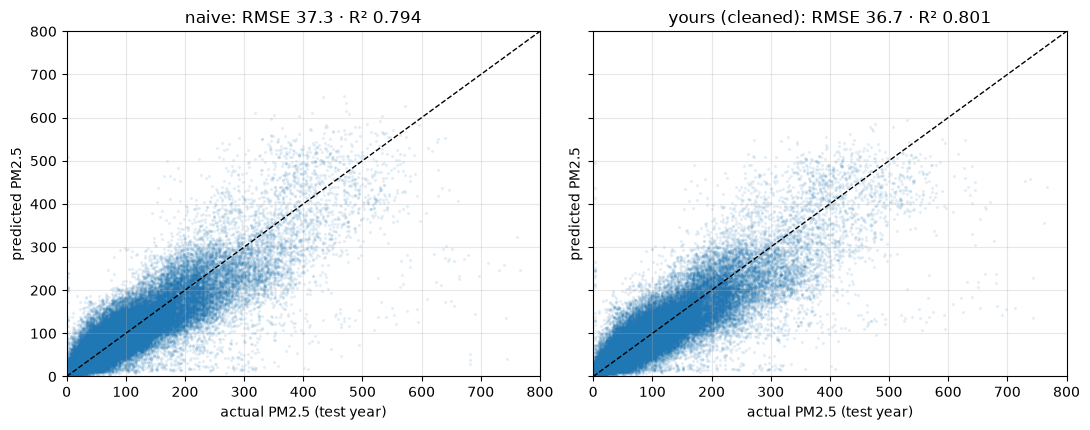

,RMSE naive,RMSE yours,gain
station,,,
Wanshouxigong,42.25,40.82,1.43
Nongzhanguan,37.32,36.03,1.29
Shunyi,40.23,39.31,0.92
Gucheng,38.80,38.00,0.80
Tiantan,39.00,38.21,0.79
Wanliu,35.68,34.90,0.78
Guanyuan,38.52,37.79,0.73
Huairou,31.57,30.90,0.67
Dongsi,40.81,40.32,0.49


In [37]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.4), sharex=True, sharey=True)
lim = [0, 800]
for a, p, name, r in [(ax[0], pred_naive, "naive", res_naive), (ax[1], pred_yours, "yours (cleaned)", res_yours)]:
    a.scatter(test_f[TARGET], p, s=2, alpha=.08)
    a.plot(lim, lim, "k--", lw=1)
    a.set_xlim(lim); a.set_ylim(lim); a.set_xlabel("actual PM2.5 (test year)"); a.set_ylabel("predicted PM2.5")
    a.set_title(f"{name}: RMSE {r['RMSE']:.1f} · R² {r['R2']:.3f}")
plt.tight_layout(); plt.show()

by_station = pd.DataFrame({
    "RMSE naive": test_f.assign(p=pred_naive).groupby("station").apply(lambda g: np.sqrt(mean_squared_error(g[TARGET], g["p"]))),
    "RMSE yours": test_f.assign(p=pred_yours).groupby("station").apply(lambda g: np.sqrt(mean_squared_error(g[TARGET], g["p"]))),
})
by_station["gain"] = by_station["RMSE naive"] - by_station["RMSE yours"]
by_station.sort_values("gain", ascending=False).round(2)

## ★ HPC bonus (+10 pts) — parallel per-station cleaning
The 12 stations are independent: run `clean_basic` + your imputation **per station** with `joblib.Parallel` (or Dask) and compare wall-time for 1, 2, 4 … workers. Report the speed-up $S_p=T_1/T_p$, efficiency $E_p=S_p/p$ and the dominant step.

In [ ]:
from joblib import Parallel, delayed
from threadpoolctl import threadpool_limits
from sklearn.impute import KNNImputer
import os
print("CPU cores on this machine:", os.cpu_count())

groups = [g for _, g in df.groupby(df["station"].str.strip().str.title())]

def knn_fill_col(piv, k=5):
    """One column: hours x stations table -> KNN-imputed table (single-threaded task)."""
    with threadpool_limits(limits=1):                      # no hidden BLAS/OpenMP threads
        imp = KNNImputer(n_neighbors=k).fit_transform(piv)
    return pd.DataFrame(imp, index=piv.index, columns=piv.columns)

def run_all(p):
    t0 = time.perf_counter()
    cleaned = Parallel(n_jobs=p)(delayed(clean_basic)(g) for g in groups)             # step 1: clean (per station)
    t1 = time.perf_counter()
    short = Parallel(n_jobs=p)(delayed(fill_short_gaps)(g) for g in cleaned)          # step 2: gaps <= 3 h (per station)
    t2 = time.perf_counter()
    d = pd.concat(short, ignore_index=True).set_index(["datetime", "station"])
    pivots = [d[c].unstack("station") for c in FILL_COLS]                             # serial: hours x stations tables
    t3 = time.perf_counter()
    filled = Parallel(n_jobs=p)(delayed(knn_fill_col)(pv) for pv in pivots)           # step 3: KNN (per column)
    t4 = time.perf_counter()
    for c, imp in zip(FILL_COLS, filled):                                             # serial: write back, only into the NaN
        d[c] = d[c].fillna(imp.stack().reindex(d.index))
    d["RAIN"] = d["RAIN"].clip(lower=0)
    t5 = time.perf_counter()
    return d.reset_index(), {"clean": t1 - t0, "short gaps": t2 - t1, "pivot (serial)": t3 - t2,
                             "KNN": t4 - t3, "write-back (serial)": t5 - t4, "total": t5 - t0}

timings = {}
for p in [1,2,4]:
    out_p, timings[p] = run_all(p)
hpc = pd.DataFrame(timings).T
hpc.index.name = "workers p"
hpc["speed-up S_p"] = hpc.loc[1, "total"] / hpc["total"]
hpc["efficiency E_p"] = hpc["speed-up S_p"] / hpc.index

a = out_p.sort_values(["station", "datetime"]).reset_index(drop=True)[FILL_COLS].to_numpy()
b = df_imp.sort_values(["station", "datetime"]).reset_index(drop=True)[FILL_COLS].to_numpy()
print("same result as the serial version:", np.allclose(a, b, equal_nan=True))
hpc.round(2)

CPU cores on this machine: 12
same result as the serial version: True


,clean,short gaps,pivot (serial),KNN,write-back (serial),total,speed-up S_p,efficiency E_p
workers p,,,,,,,,
1,8.75,2.38,4.02,78.60,0.33,94.08,1.00,1.00
2,3.35,1.02,1.09,47.04,0.29,52.78,1.78,0.89
4,3.47,0.71,0.78,43.96,0.33,49.25,1.91,0.48


## Export for Lecture 2
Save your cleaned (and imputed) training years — it is the **input of the Week-2 AI Methods Shoot-out**.

In [39]:
df_clean.drop(columns=["datetime"]).to_csv(f"beijing_clean_team{TEAM_ID}.csv.gz", index=False)

## Report template (1 page)
1. **Findings** — the issue log (dimension · station · column · period · problem · rows · fix · why).
2. **Key decisions** — imputation per gap length (Task 3 numbers), outlier policy, transforms, dropped rows and possible bias (MNAR in smog?).
3. **Impact** — naive vs cleaned test-year RMSE / MAE / R² and one plot.
4. **Lessons** — what would you ask the agency to change in how stations export data?
5. *(bonus)* HPC timings and speed-up.

<div style="background:linear-gradient(120deg,#0a2a5c,#1c5aa6);color:#e6eef8;padding:14px 22px;border-radius:10px;border-top:4px solid #d49a2a;margin-top:10px;">
<b style="color:#ffd98e;">Al-Khawarizmi Tour · Online Hackathon HPC &amp; AI</b> · Oct 3 – Nov 7, 2026 · 100% online<br>
<i>From the past to the future… Science without borders. Your ideas. A bigger tomorrow.</i> · © 2026 Dr. Rafik Borji</div>